# 05 · MATH_MAP: ein Text, eine Formel, eine Datenbank

**NHyDB-0.27.1-Notebook-Reihe · v1**

Mit MATH_MAP entscheidest **du** über eine Formel, wo ein Wert gespeichert wird. Die Rechnung bestimmt den Ort; der Inhalt ist davon unabhängig. Wir zerschneiden einen Text in Stücke, verteilen sie mit einer einfachen Formel über das Dynadron und setzen den Text bytegenau wieder zusammen – danach baust du eigene Formeln.

> **Für wen ist das?** Dieses Notebook beginnt mit einer kurzen Einführung und geht dann in ausführbare Beispiele über. **Neu bei NHyDB?** Lies von oben nach unten – jede Idee wird eingeführt, bevor sie verwendet wird. **Kennst du die Grundlagen schon?** Überspringe die mit 📘 *Hintergrund* markierten Abschnitte und springe zu den mit ▶ markierten Experimenten. Alle Zellen laufen von oben nach unten; optionale Vertiefungen sind mit ⏩ *Vertiefung* markiert.

**Was du lernst**

* wie ein MATH-Layout aus Eingaben eine Zelle macht: `inputs → (u, V, side) → (R, u, v, lane) → N`
* den Unterschied zwischen dem **Adressgeber** (der Formel) und den **Nutzdaten** (den Daten)
* einen zweiten Weg: eine Formel, die die Zahl `N` selbst erzeugt – und warum die Engine Quadrate zurückweist
* warum eine Zellnummer immer eindeutig ist, eine selbst gewählte Formel aber trotzdem **kollidieren** kann
* die Regeln: `dry_run`, erlaubte Ausdrücke, Konflikte, eingefrorene Abbildungen, exklusive Realms

**Vorher empfohlen:** [01](01_the_address_is_the_identity_v1.ipynb) und [02](02_from_address_to_data_v1.ipynb).

### Einrichtung

Die nächste Zelle prüft die Umgebung und definiert ein paar kleine Zeichenhilfen für dieses
Notebook. Sie ist eingeklappt, weil es darin nicht um NHyDB selbst geht – du kannst sie aber
gern öffnen. Jede Datenbank in diesem Notebook liegt in einem temporären Ordner, der am Ende
gelöscht wird.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_staircase(ax, g_max=10, highlight=(), annotate=True, title=None, g_min=1):
    """Every natural number 1 … g_max·(g_max+1)−1 in its group row.

    Row G holds the numbers G(G−1) … G(G+1)−1. The horizontal position is N − G²:
    NL cells sit at −u (left of the square G²), NR cells at +v (right of it).
    """
    highlight = set(highlight)
    for g in range(g_min, g_max + 1):
        for n in range(max(1, g * (g - 1)), g * (g + 1)):
            k = kind_of(n)
            x, y = n - g * g, -g
            face = COLORS[k]
            alpha = 1.0 if k in ("GZ", "N0") else 0.85
            ax.add_patch(Rectangle((x - 0.47, y - 0.42), 0.94, 0.84, facecolor=face, alpha=alpha,
                                   edgecolor=COLORS["attention"] if n in highlight else "white",
                                   linewidth=2.6 if n in highlight else 0.5))
            if annotate:
                ax.text(x, y, str(n), ha="center", va="center", color="white",
                        fontsize=7 if n < 100 else 6, fontweight="bold")
    ax.set_xlim(-g_max - 1, g_max)
    ax.set_ylim(-g_max - 0.8, -g_min + 0.8)
    ax.set_yticks([-g for g in range(g_min, g_max + 1)])
    ax.set_yticklabels([f"G={g}" for g in range(g_min, g_max + 1)])
    ax.set_xlabel("position in the group:  N − G²   (NL: −u   ·   GZ: 0   ·   NR: +v)")
    ax.axvline(0, color=COLORS["GZ"], lw=0.8, ls=":", zorder=0)
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
    ax.spines["left"].set_visible(False)
    handles = [Rectangle((0, 0), 1, 1, color=COLORS[k]) for k in ("N0", "NL", "GZ", "NR")]
    ax.legend(handles, [KIND_LABEL[k] for k in ("N0", "NL", "GZ", "NR")], ncol=4,
              loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=9)
    if title:
        ax.set_title(title)


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import pandas as pd
from nhydb.math import MathExpression, MathMap, MathMapLayoutSpec, dry_run


def report_table(report):
    """The most important numbers of a dry_run report as a small table."""
    keys = ["total", "valid", "invalid", "unique_cells", "collisions", "logical_realms", "nl_count", "nr_count"]
    return pd.DataFrame([{k: getattr(report, k) for k in keys}])

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Hintergrund: eine Formel als Adressgeber

In Notebook 02 hat das CLASSIC-Layout den Datensatz `k` bei `u = k` abgelegt. Ein **MATH-Layout**
ersetzt diese feste Regel durch **deine eigenen Formeln**. Für jedes Eingabetupel `(x1, x2, …)`
berechnet es

* `u` – eine positive ganze Zahl,
* `V` – eine positive ganze Zahl, die *globale* Position (sie darf größer als ein Realm sein),
* `side` – die Lane, NL (0) oder NR (1).

Die Engine zerlegt `V` in einen logischen Realm und ein lokales `v` (ein Realm fasst `10^100`
Positionen), ordnet ihm einen freien physischen Realm zu und speichert den Wert in dieser Zelle.
Die Zahl `N` der Zelle folgt aus der physischen Adresse, genau wie in Notebook 01.

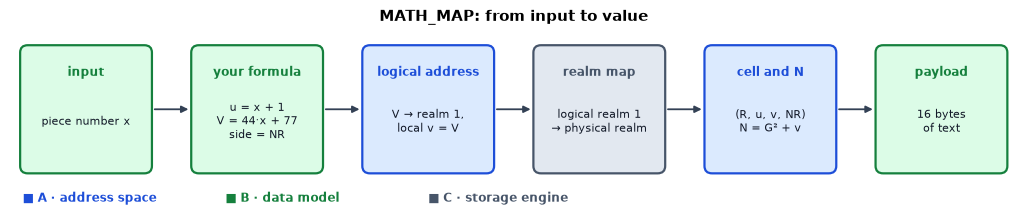

In [2]:
fig, ax = plt.subplots(figsize=(13, 2.4))
plot_path(ax, [
    ("B", "input", "piece number x"),
    ("B", "your formula", "u = x + 1\nV = 44·x + 77\nside = NR"),
    ("A", "logical address", "V → realm 1,\nlocal v = V"),
    ("C", "realm map", "logical realm 1\n→ physical realm"),
    ("A", "cell and N", "(R, u, v, NR)\nN = G² + v"),
    ("B", "payload", "16 bytes\nof text"),
], title="MATH_MAP: from input to value")
plt.show()

---
# Teil A · Das KISS-Experiment: 100 Wörter, echte Zellen

**Frage:** Kann eine Formel entscheiden, wohin die Stücke eines Textes kommen – und bekommen wir
den Text exakt zurück?

### A1 · Der Text und seine Stücke

Ein ausgedachter Text mit Satzzeichen, einem Zeilenumbruch, Umlauten und ein paar Symbolen. Wir
speichern seine **Bytes** (UTF-8), zerschnitten in Stücke zu 16 Bytes; das letzte Stück darf
kürzer sein.

In [3]:
TEXT = (
    "In the library of numbers there are no shelves and no catalogue. Every page has a place "
    "that can be computed: take a page number, apply a formula, and the formula tells you which "
    "cell of the Dynadron holds it. Nothing has to be looked up, nothing has to be counted.\n"
    "This little story was cut into pieces of sixteen bytes. Each piece was sent to the cell "
    "that the formula chose for it – far away from its neighbours. To read the story again, we "
    "simply ask the same formula for the same piece numbers, one after another. Even “quotes”, "
    "umlauts like Größe and symbols like π ≈ 3.14159 come back exactly."
)
CHUNK = 16                                          # ▶ Try it: piece size in bytes

original = TEXT.encode("utf-8")
pieces = [original[i:i + CHUNK] for i in range(0, len(original), CHUNK)]
print(f"{len(TEXT.split())} words, {len(TEXT)} characters, {len(original)} bytes → {len(pieces)} pieces")
print("first pieces:", pieces[:3])

113 words, 600 characters, 611 bytes → 39 pieces
first pieces: [b'In the library o', b'f numbers there ', b'are no shelves a']


### A2 · Die Formel – geprüft, bevor irgendetwas geschrieben wird

Stück Nummer `x = 0, 1, 2, …` kommt nach

```text
u    = x + 1
V    = 44·x + 77
side = NR
```

`dry_run` wertet die Formel für alle Eingaben **ohne Datenbank** aus und meldet ungültige
Zeilen, Kollisionen und die Realms, die gebraucht würden.

In [4]:
text_map = MathMap.compile("text", ("x",), u="x + 1", V="44*x + 77", side="NR")
inputs = [(x,) for x in range(len(pieces))]

report = dry_run(text_map, inputs)
report_table(report)

,total,valid,invalid,unique_cells,collisions,logical_realms,nl_count,nr_count
0,39,39,0,39,0,"(1,)",0,39


In [5]:
assert report.valid == len(pieces) and report.collisions == 0 and report.invalid == 0
print("All pieces get their own valid cell – we can write.")

All pieces get their own valid cell – we can write.


### A3 · Schreiben, schließen, wieder öffnen, lesen

Wir legen ein MATH-Layout mit dem Nutzdatentyp `bytes` an, schreiben alle Stücke in einem Batch
und committen. Dann wird die Datenbank geschlossen – und wieder geöffnet, als wäre es ein anderes
Programm, das nur die **Layout-ID** und die **Formeleingaben** `x = 0, 1, 2, …` kennt.

In [6]:
PATH_A = db_path("story.nhydb")

with nhydb.create(PATH_A) as db:
    db.create_math_layout(MathMapLayoutSpec("text", text_map, 64), layout_id=1, payload_type="bytes")
    write_report = db.put_math_batch(1, [((x,), piece) for x, piece in enumerate(pieces)], commit=True)
print(write_report)

{'cells': 39, 'blocks': 1, 'bytes': 893, 'new_realms': 1, 'mapped_realms': 1, 'realm_extents': [{'logical_start': 1, 'logical_end': 1, 'physical_start': 1, 'physical_end': 1}]}


In [7]:
rows = []
with nhydb.open(PATH_A) as db:                       # a fresh open
    recovered = b"".join(db.get_math(1, (x,)) for x in range(len(pieces)))
    for x, piece in enumerate(pieces):
        c = db.get_math_cell(1, (x,))
        n = nhydb.dynadron_n(c["_realm"], c["_u"], c["_v"], c["_lane"])
        rows.append({"x": x, "bytes": f"{x * CHUNK}–{x * CHUNK + len(piece) - 1}", "R_phys": c["_realm"],
                     "u": c["_u"], "v": c["_v"], "lane": c["_lane_name"], "N": n,
                     "piece": piece.decode("utf-8", errors="replace")})

cells = pd.DataFrame(rows).set_index("x")
assert recovered == original
print("recovered == original:", recovered == original)
print()
print(recovered.decode("utf-8"))

recovered == original: True

In the library of numbers there are no shelves and no catalogue. Every page has a place that can be computed: take a page number, apply a formula, and the formula tells you which cell of the Dynadron holds it. Nothing has to be looked up, nothing has to be counted.
This little story was cut into pieces of sixteen bytes. Each piece was sent to the cell that the formula chose for it – far away from its neighbours. To read the story again, we simply ask the same formula for the same piece numbers, one after another. Even “quotes”, umlauts like Größe and symbols like π ≈ 3.14159 come back exactly.


In [8]:
cells

,bytes,R_phys,u,v,lane,N,piece
x,,,,,,,
0,0–15,1,1,77,NR,6161,In the library o
1,16–31,1,2,121,NR,15250,f numbers there
2,32–47,1,3,165,NR,28389,are no shelves a
3,48–63,1,4,209,NR,45578,nd no catalogue.
4,64–79,1,5,253,NR,66817,Every page has
5,80–95,1,6,297,NR,92106,a place that can
6,96–111,1,7,341,NR,121445,be computed: ta
7,112–127,1,8,385,NR,154834,ke a page number
8,128–143,1,9,429,NR,192273,", apply a formul"


**Was ist passiert?** Jedes Stück ist in der Zelle gelandet, die die Formel gewählt hat – und kam
in der ursprünglichen Reihenfolge zurück, weil wir `x = 0, 1, 2, …` in dieser Reihenfolge
abgefragt haben. Die **Reihenfolge ist die Reihenfolge der Eingaben**, nicht die Reihenfolge von
`N` und nicht die Reihenfolge der Bytes in der Datei.

### A4 · Ansehen: verstreut und wieder zusammengesetzt

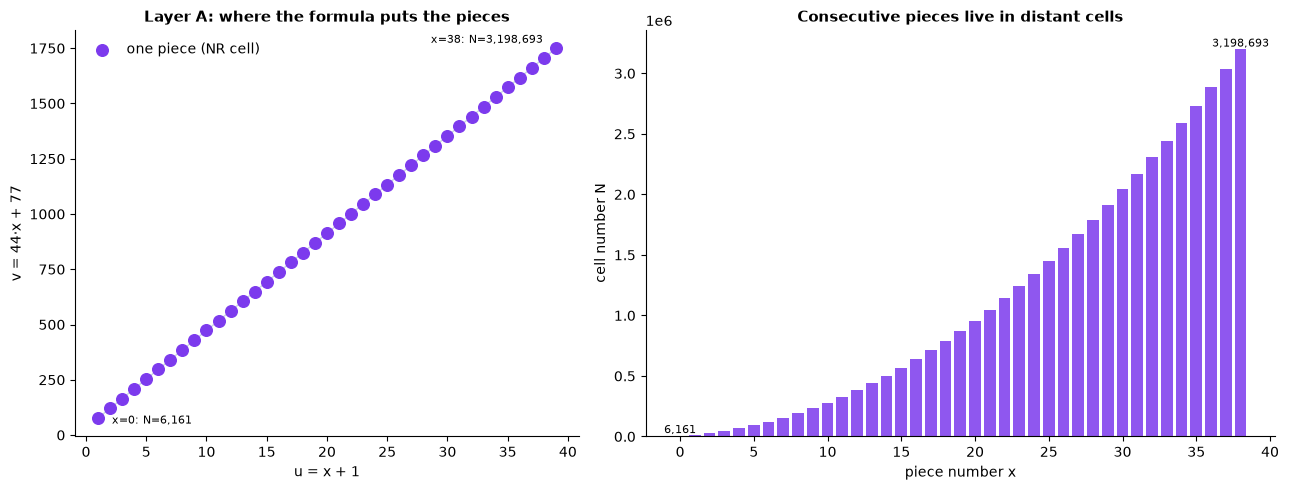

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})

# left: the cells in the (u, v) plane – the formula draws a straight line
ax1.plot(cells["u"], cells["v"], "-", color="#cbd5e1", lw=1, zorder=1)
ax1.scatter(cells["u"], cells["v"], s=70, color=COLORS["NR"], zorder=2, label="one piece (NR cell)")
for x, offset in ((0, (10, -4)), (len(cells) - 1, (-90, 4))):
    ax1.annotate(f"x={x}: N={cells.loc[x, 'N']:,}", (cells.loc[x, "u"], cells.loc[x, "v"]),
                 textcoords="offset points", xytext=offset, fontsize=8)
ax1.set_xlabel("u = x + 1")
ax1.set_ylabel("v = 44·x + 77")
ax1.set_title("Layer A: where the formula puts the pieces")
ax1.legend(frameon=False, loc="upper left")

# right: the numbers N of consecutive pieces are far apart
ax2.bar(cells.index, cells["N"], color=COLORS["NR"], alpha=0.85)
ax2.set_xlabel("piece number x")
ax2.set_ylabel("cell number N")
ax2.set_title("Consecutive pieces live in distant cells")
for x in (0, len(cells) - 1):
    ax2.text(x, cells.loc[x, "N"], f"{cells.loc[x, 'N']:,}", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

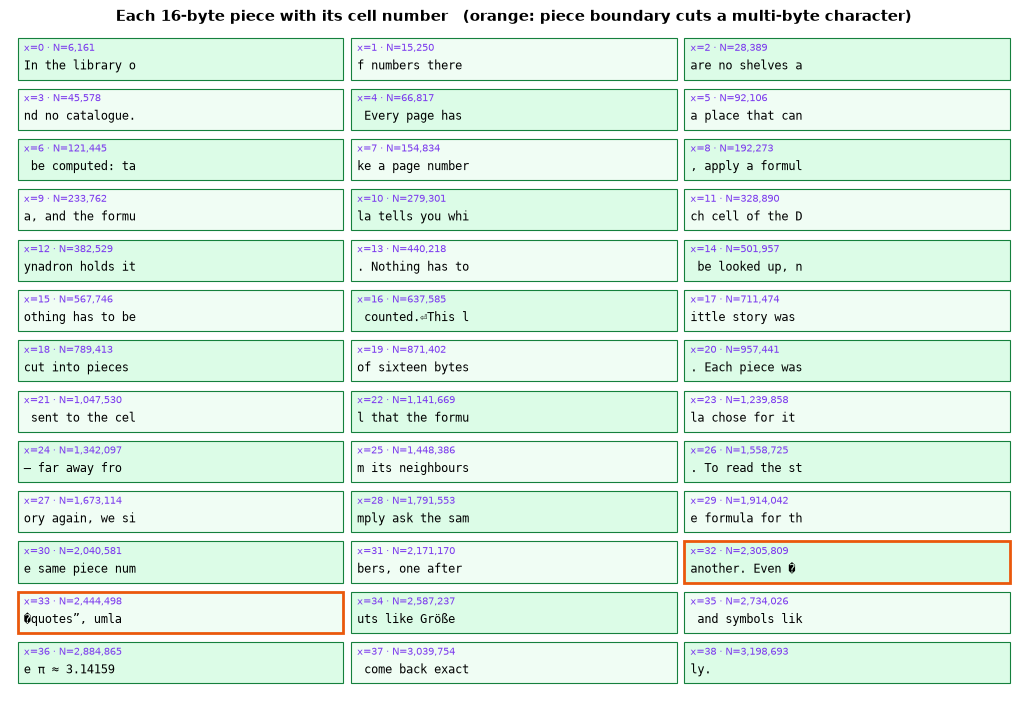

In [10]:
# The text as a mosaic: each tile is one piece with the cell number that stores it.
per_row = 3
n_rows = (len(cells) + per_row - 1) // per_row
fig, ax = plt.subplots(figsize=(13, 0.62 * n_rows + 0.6))
for x, row in cells.iterrows():
    col, line = x % per_row, x // per_row
    shown = row["piece"].replace("\n", "⏎")
    split = "�" in shown
    ax.add_patch(Rectangle((col * 4.35, -line - 0.9), 4.25, 0.82, facecolor=COLORS["B_light"] if x % 2 == 0 else "#f0fdf4",
                           edgecolor=COLORS["attention"] if split else COLORS["B"], lw=2 if split else 0.8))
    ax.text(col * 4.35 + 0.08, -line - 0.33, f"x={x} · N={row['N']:,}", fontsize=7, color=COLORS["NR"])
    ax.text(col * 4.35 + 0.08, -line - 0.70, repr(shown)[1:-1], fontsize=8.5, family="monospace")
ax.set_xlim(-0.1, per_row * 4.35)
ax.set_ylim(-n_rows - 0.15, 0.1)
ax.axis("off")
ax.set_title("Each 16-byte piece with its cell number   (orange: piece boundary cuts a multi-byte character)")
plt.show()

**Was ist passiert? – drei Unterscheidungen, auf die es ankommt**

* **Adressgeber vs. Nutzdaten:** Die Formel entscheidet nur, *wo*; die Bytes des Textes sind
  davon völlig unabhängig. Auf diese Weise ließen sich beliebige Daten speichern – Texte,
  Dateien, Messwerte.
* **Bytes, nicht Zeichen:** Einige Kacheln sind orange umrandet – die 16-Byte-Grenze schneidet
  ein Mehrbyte-Zeichen wie `ö`, `π` oder `“` in der Mitte durch. Allein angezeigt ist so ein
  Stück kein gültiger Text (`�`). Weil wir die **Bytes** gespeichert haben und sie in der
  richtigen Reihenfolge zusammenfügen, kommt der Text einwandfrei zurück.
* **`N` ist keine Position in der Datei:** `N` benennt die Zelle mathematisch. Wo die Bytes
  physisch in `story.nhydb` liegen, ist Sache der Speicher-Engine (Schicht C).

**Ah – die Formel *ist* der Index des Textes. Gleiche Formel + gleiche Eingaben = gleicher Text.**

---
# Teil B · Ein zweiter Weg: Die Formel berechnet `N` selbst

**Frage:** Was ist, wenn eine Rechnung keine Koordinaten liefert, sondern direkt eine **Zahl**
`y` – und `y` die Zellnummer `N` *sein* soll?

Nimm `y = 44·x + 77`. Um einen Wert bei `N = y` zu speichern, brauchen wir die Umkehrabbildung
aus Notebook 01 (`N → u, v, lane`). Sie lässt sich **in der MATH-Ausdruckssprache selbst**
schreiben – bedingte Ausdrücke sind dafür nicht nötig:

```text
m = isqrt(y),   d = y − m²,   s = min(1, max(0, d − m))     (s = 1 for NL, 0 for NR)
u    = m − d + s·(m + 1)
V    = d − s·m
side = d < m                                              (True = NR, False = NL)
```

In [11]:
y = "(44*x + 77)"
m = f"isqrt({y})"
d = f"({y} - {m}*{m})"
s = f"min(1, max(0, {d} - {m}))"
n_map = MathMap.compile("n_candidate", ("x",), u=f"{m} - {d} + {s}*({m} + 1)", V=f"{d} - {s}*{m}",
                        side=f"{d} < {m}")

rows = []
for x in range(30):
    yv = 44 * x + 77
    try:
        t = n_map.target(x)
        n = nhydb.dynadron_n(1, t.u, t.v_local, t.side)
        assert n == yv                                   # the cell number is exactly y
        rows.append({"x": x, "y": yv, "kind": kind_of(yv), "u": t.u, "v": t.v_local,
                     "lane": "NR" if t.side else "NL", "N of cell": n})
    except nhydb.MathDomainError as e:
        rows.append({"x": x, "y": yv, "kind": kind_of(yv), "u": "–", "v": "–", "lane": "–",
                     "N of cell": f"rejected: {e}"})
candidates = pd.DataFrame(rows).set_index("x")
candidates.head(8)

,y,kind,u,v,lane,N of cell
x,,,,,,
0,77,NL,4,5,NL,77
1,121,GZ,–,–,–,rejected: V must be a positive integer
2,165,NL,4,9,NL,165
3,209,NR,1,13,NR,209
4,253,NL,3,13,NL,253
5,297,NR,9,8,NR,297
6,341,NR,1,17,NR,341
7,385,NL,15,5,NL,385


In [12]:
print(candidates[candidates["kind"].isin(["GZ", "N0"])])

       y kind  u  v lane                               N of cell
x                                                               
1    121   GZ  –  –    –  rejected: V must be a positive integer
23  1089   GZ  –  –    –  rejected: V must be a positive integer


**Was ist passiert?** Für `x = 1` liefert die Formel `y = 121 = 11²` – einen **GZ-Punkt**, keine
Zelle. Die Engine weist ihn von sich aus zurück: Die Umkehrung bräuchte `V = 0`, und MATH-Layouts
verlangen `V > 0` (`MathDomainError`). Dasselbe passiert bei `x = 23` (`y = 1089 = 33²`).
N0-Punkte würden an `u = 0` scheitern. **Die Datenbank kennt die Grenzpunkte des Dynadrons.**

### Ansehen: die Kandidaten auf der Treppe

Jeder Kandidat `y` wird an seinem Platz in der Treppe aus Notebook 01 gezeichnet (waagrecht:
`y − G²`, senkrecht: Gruppe `G`). Quadrate liegen genau auf der roten Mittellinie.

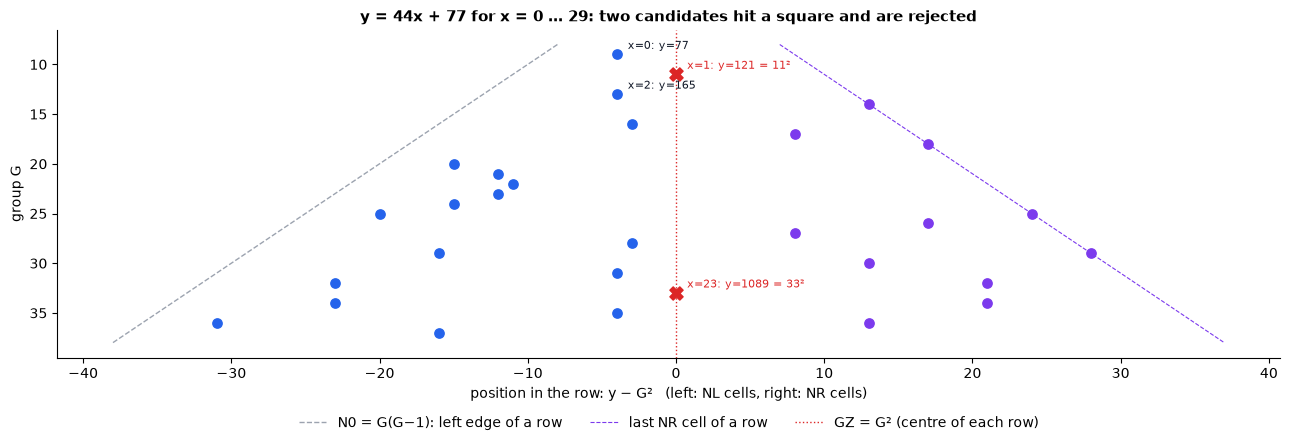

In [13]:
fig, ax = plt.subplots(figsize=(13, 4.6))
for x, row in candidates.iterrows():
    yv = row["y"]
    g = group_of(yv)
    k = row["kind"]
    ax.scatter(yv - g * g, g, s=90 if k in ("GZ", "N0") else 45, color=COLORS[k],
               marker="X" if k in ("GZ", "N0") else "o", zorder=3)
    if k in ("GZ", "N0") or x < 3:
        ax.annotate(f"x={x}: y={yv}" + (" = %d²" % math.isqrt(yv) if k == "GZ" else ""),
                    (yv - g * g, g), textcoords="offset points", xytext=(8, 4), fontsize=8,
                    color=COLORS["GZ"] if k == "GZ" else "#111827")
gs = [group_of(v) for v in candidates["y"]]
g_line = range(min(gs) - 1, max(gs) + 2)
ax.plot([-g for g in g_line], list(g_line), color=COLORS["N0"], lw=1, ls="--", label="N0 = G(G−1): left edge of a row")
ax.plot([g - 1 for g in g_line], list(g_line), color=COLORS["NR"], lw=0.8, ls="--", label="last NR cell of a row")
ax.axvline(0, color=COLORS["GZ"], lw=1, ls=":", label="GZ = G² (centre of each row)")
ax.invert_yaxis()
ax.set_xlabel("position in the row: y − G²   (left: NL cells, right: NR cells)")
ax.set_ylabel("group G")
ax.set_title("y = 44x + 77 for x = 0 … 29: two candidates hit a square and are rejected")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
plt.tight_layout()
plt.show()

### B2 · Den Text mit der `N`-Kandidaten-Regel speichern

Zwei der ersten 30 Kandidaten sind keine Zellen, also brauchen wir eine **dokumentierte Regel** –
nichts darf stillschweigend übersprungen werden. Unsere Regel:

> Stück Nummer `i` wird beim `i`-ten **gültigen** Kandidaten `x` gespeichert; ungültige Kandidaten
> werden auf feste, reproduzierbare Weise übersprungen (welche ungültig sind, sagt uns die
> Engine selbst).

Wer liest, wendet genau dieselbe Regel an. In einer frischen Datenbank bekommt das MATH-Layout
den physischen Realm 1, deshalb ist die Zellnummer genau `N = y`.

In [14]:
def valid_candidates(count):
    """The first `count` inputs x whose candidate y is a real cell (deterministic rule)."""
    out, x = [], 0
    while len(out) < count:
        try:
            n_map.target(x)
            out.append(x)
        except nhydb.MathDomainError:
            pass                                          # GZ or N0 – documented skip
        x += 1
    return out


xs = valid_candidates(len(pieces))
print("skipped candidates:", sorted(set(range(xs[-1] + 1)) - set(xs)))

PATH_B = db_path("story_by_n.nhydb")
with nhydb.create(PATH_B) as db:
    db.create_math_layout(MathMapLayoutSpec("n_candidate", n_map, 64), layout_id=1, payload_type="bytes")
    db.put_math_batch(1, [((x,), piece) for x, piece in zip(xs, pieces)], commit=True)

with nhydb.open(PATH_B) as db:
    again = b"".join(db.get_math(1, (x,)) for x in valid_candidates(len(pieces)))
    first = db.get_math_cell(1, (xs[0],))
    n_first = nhydb.dynadron_n(first["_realm"], first["_u"], first["_v"], first["_lane"])
    by_number = db.get_n(44 * xs[2] + 77, mode="cell")["value"]   # read piece 2 only by its number y

assert again == original and n_first == 44 * xs[0] + 77 and by_number == pieces[2]
print(f"text recovered: {again == original};  piece 0 lives at N = {n_first} = 44·{xs[0]} + 77")
print(f"piece 2 read directly by its number y = {44 * xs[2] + 77}: {by_number!r}")

skipped candidates: [1, 23]
text recovered: True;  piece 0 lives at N = 77 = 44·0 + 77
piece 2 read directly by its number y = 209: b'are no shelves a'


**Was ist passiert?** Zwei verschiedene Abbildungen, ein Text:

| | natives MATH_MAP (Teil A) | `N`-Kandidat (Teil B) |
|---|---|---|
| die Formel liefert | Koordinaten `(u, V, side)` | eine Zahl `y` |
| die Zelle ist | `(R, u, v, side)` | die Zelle mit der Zahl `y` |
| ungültige Eingaben | `u ≤ 0` oder `V ≤ 0` | zusätzlich alle GZ- und N0-Zahlen |
| ein Stück lesen über | Layout-ID + `x` | Layout-ID + `x` – **oder einfach `get_n(y)`** |

> `N == y` gilt, weil das Layout auf dem physischen Realm 1 gelandet ist. In einer Datenbank,
> die Realm 1 schon für etwas anderes nutzt, verschiebt die Realm-Zuordnung das Layout (Teil D),
> und die Zahlen ändern sich.

---
# Teil C · ▶ Formellabor

**Ändere es:** Wähle eine der vorbereiteten Formeln oder schreibe eine eigene und führe dann die
beiden Zellen aus. `dry_run` prüft alles, bevor auch nur ein Byte geschrieben wird; das Diagramm
zeigt, wo die Eingaben landen würden, Kollisionen in Orange und ungültige Eingaben als rote Kreuze.

In [15]:
EXAMPLES = {
    "linear":      dict(u="x + 1",          V="44*x + 77",       side="NR"),
    "quadratic":   dict(u="x + 1",          V="x*x + 1",         side="NL"),
    "gcd":         dict(u="gcd(x, 12) + 1", V="x + 1",           side="x % 2"),
    "colliding":   dict(u="x % 4 + 1",      V="x // 8 + 1",      side="NL"),
    "corrected":   dict(u="x % 4 + 1",      V="x // 4 + 1",      side="NL"),
    "invalid":     dict(u="x - 5",          V="x + 1",           side="NR"),
}

# ▶ Try it: choose an example or write your own expressions
CHOICE = "colliding"
X_RANGE = range(0, 24)

formula = EXAMPLES[CHOICE]
lab_map = MathMap.compile(CHOICE, ("x",), **formula)
lab = dry_run(lab_map, [(x,) for x in X_RANGE])
print(f"{CHOICE}: u = {formula['u']},  V = {formula['V']},  side = {formula['side']}")
report_table(lab)

colliding: u = x % 4 + 1,  V = x // 8 + 1,  side = NL


,total,valid,invalid,unique_cells,collisions,logical_realms,nl_count,nr_count
0,24,24,0,12,12,"(1,)",24,0


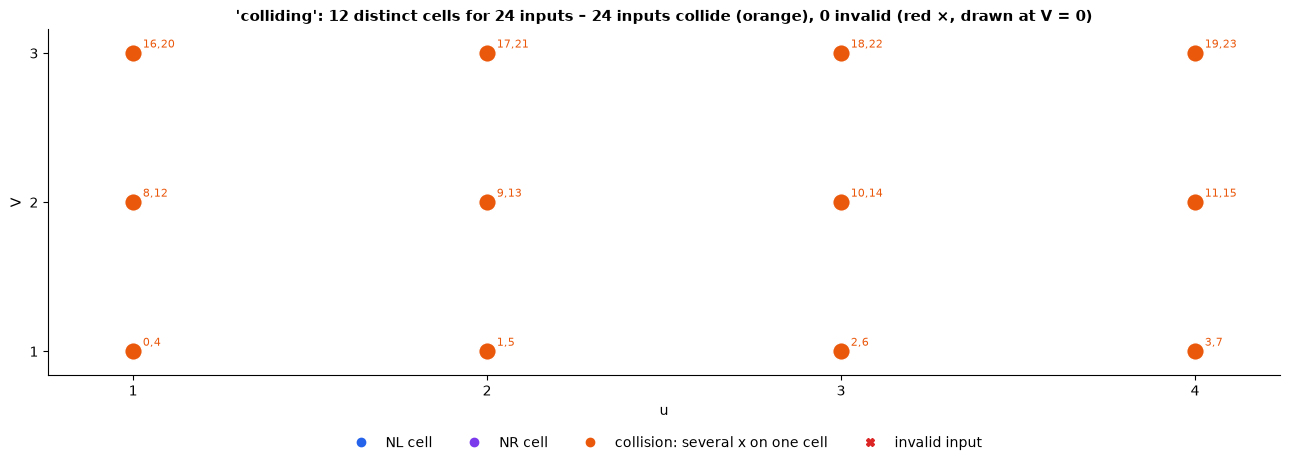

In [16]:
targets, invalid = {}, []
for x in X_RANGE:
    try:
        t = lab_map.target(x)
        targets.setdefault((t.u, t.V_global, t.side), []).append(x)
    except nhydb.MathError:
        invalid.append(x)

fig, ax = plt.subplots(figsize=(13, 4.8))
for (u, V, side), xs_here in targets.items():
    hit = len(xs_here) > 1
    ax.scatter(u, V, s=60 + 50 * len(xs_here), color=COLORS["attention"] if hit else COLORS["NR" if side else "NL"],
               edgecolor="white", zorder=3)
    ax.annotate(",".join(map(str, xs_here)), (u, V), textcoords="offset points", xytext=(7, 4), fontsize=8,
                color=COLORS["attention"] if hit else "#111827")
for x in invalid:
    ax.scatter(x, 0, marker="X", s=70, color=COLORS["bad"], zorder=3)
ax.set_xlabel("u")
ax.set_ylabel("V")
n_coll = sum(len(v) for v in targets.values() if len(v) > 1)
ax.set_title(f"'{CHOICE}': {len(targets)} distinct cells for {len(X_RANGE)} inputs – "
             f"{n_coll} inputs collide (orange), {len(invalid)} invalid (red ×, drawn at V = 0)")
handles = [plt.Line2D([], [], marker="o", ls="", color=COLORS[k]) for k in ("NL", "NR", "attention")]
handles.append(plt.Line2D([], [], marker="X", ls="", color=COLORS["bad"]))
ax.legend(handles, ["NL cell", "NR cell", "collision: several x on one cell", "invalid input"],
          frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
ax.margins(0.08)
plt.tight_layout()
plt.show()

**Was ist passiert?** Mit `colliding` landen die Eingaben `x = 0, 4` (und weitere) in **derselben**
Zelle: Die Formel `u = x % 4 + 1, V = x // 8 + 1` vergisst Information. Die Zellnummern selbst
kollidieren nie – **die Formel tut es**. `corrected` behält alle Information (`x // 4` statt
`x // 8`), und jede Eingabe bekommt ihre eigene Zelle. Probiere `invalid` aus, um Eingaben mit
`u ≤ 0` zu sehen.

### C2 · Die Regeln der Ausdruckssprache

Erlaubt ist nur Ganzzahlarithmetik: `+ - * // % **`, Vergleiche, `and`/`or`/`not` und die
Funktionen `abs`, `gcd`, `lcm`, `isqrt`, `min`, `max`. Alles andere wird schon beim Kompilieren
der Formel zurückgewiesen:

In [17]:
from nhydb.math import get_math_max_intermediate_bits, set_math_max_intermediate_bits

for source in ("x / 2", "x if x > 0 else 1", "x.bit_length()", "isqrt(x) + gcd(x, 12)"):
    try:
        MathExpression.compile(source, ("x",))
        print(f"{source!r:28} → accepted")
    except nhydb.MathSyntaxError as e:
        print(f"{source!r:28} → MathSyntaxError: {e}")

print("\nbig integers are exact:", MathExpression.compile("x ** 50", ("x",)).evaluate(x=10) == 10**50)
print("limit for intermediate results:", get_math_max_intermediate_bits(), "bits")
old = get_math_max_intermediate_bits()
set_math_max_intermediate_bits(64)
try:
    MathExpression.compile("2 ** x", ("x",)).evaluate(x=100)
except nhydb.MathDomainError as e:
    print("with a 64-bit limit, 2**100 →", type(e).__name__)
finally:
    set_math_max_intermediate_bits(old)

'x / 2'                      → MathSyntaxError: syntax element Div is not allowed
'x if x > 0 else 1'          → MathSyntaxError: syntax element IfExp is not allowed
'x.bit_length()'             → MathSyntaxError: only approved mathematical functions are allowed
'isqrt(x) + gcd(x, 12)'      → accepted

big integers are exact: True
limit for intermediate results: 1048576 bits
with a 64-bit limit, 2**100 → MathDomainError


### C3 · Die Regeln eines MATH-Layouts in der Datenbank

Ein MATH-Layout schützt seine Zellen. Jede der folgenden Regeln wird absichtlich ausgelöst und
geprüft:

| Situation | Reaktion |
|---|---|
| dieselbe Eingabe zweimal schreiben | `MathCellConflictError` – kein stilles Überschreiben |
| `overwrite=True` | neuer Wert (ein neuer Zustand; der alte bleibt in der Append-only-Datei) |
| eine fehlerhafte Zeile in einem Batch | der **ganze Batch** wird zurückgerollt |
| die Formel nach dem ersten Schreiben ändern | `MappingFrozenError` |
| direkt in einen MATH-Realm schreiben | `SchemaError` – der Realm gehört dem Layout |

In [18]:
PATH_C = db_path("rules.nhydb")
with nhydb.create(PATH_C) as db:
    db.create_math_layout(MathMapLayoutSpec("text", text_map, 64), layout_id=1, payload_type="utf8")
    db.put_math(1, (0,), "first", commit=True)

    try:
        db.put_math(1, (0,), "second")
    except nhydb.MathCellConflictError as e:
        print("conflict      →", e)

    db.put_math(1, (0,), "second", overwrite=True, commit=True)
    print("overwrite     →", db.get_math(1, (0,)))
    assert db.get_math(1, (0,)) == "second"

    try:
        db.put_math_batch(1, [((5,), "good row"), ((-3,), "bad row: u = -2")])
    except nhydb.MathDomainError as e:
        print("batch error   →", e, "| row x=5 stored?", db.get_math(1, (5,)))
    assert db.get_math(1, (5,)) is None

    try:
        db.replace_math_spec(1, MathMapLayoutSpec("text", n_map, 64))
    except nhydb.MappingFrozenError as e:
        print("frozen        →", e)

    realm = db.get_math_cell(1, (0,))["_realm"]
    try:
        db.put_points(realm, [(1, 1, "sneaking in", "utf8")])
    except nhydb.SchemaError as e:
        print("exclusive     →", e)

conflict      → Target cell (1, 1, 77, 1) is already occupied
overwrite     → second
batch error   → u must be a positive integer | row x=5 stored? None
frozen        → MATH 1 is frozen after the first write
exclusive     → Realm 1 belongs exclusively to MATH layout 1; direct put_points blocked


---
# Teil D · ⏩ Logische und physische Realms

Die Formel kennt nur **logische** Realms (`V` jenseits von `10^100` bedeutet logischer Realm 2,
3, …). Die Engine bildet sie auf **freie physische** Realms ab und besitzt diese exklusiv. In einer
Datenbank, in der Realm 1 schon von gewöhnlichen Daten belegt ist, wandert unser Text-Layout:

In [19]:
PATH_D = db_path("shared.nhydb")
with nhydb.create(PATH_D) as db:
    db.create_realm(1, "ordinary data")
    db.put_cell(1, 1, 1, "something else", type="utf8")
    db.create_math_layout(MathMapLayoutSpec("text", text_map, 64), layout_id=1, payload_type="bytes")
    db.put_math_batch(1, [((x,), p) for x, p in enumerate(pieces)], commit=True)
    info = db.describe_math(1)
    c = db.get_math_cell(1, (0,))

print("realm extents:", info["realm_extents"])
print(f"piece 0: logical realm {c['_logical_realm']} → physical realm {c['_realm']}, "
      f"N = {nhydb.dynadron_n(c['_realm'], c['_u'], c['_v'], c['_lane'])}")
assert c["_realm"] == 2 and c["_logical_realm"] == 1

realm extents: [{'logical_start': 1, 'logical_end': 1, 'physical_start': 2, 'physical_end': 2}]
piece 0: logical realm 1 → physical realm 2, N = 100000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000001570000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000006161


Formel und Eingaben sind unverändert – das Layout findet nach wie vor jedes Stück –, aber die
Zellnummern liegen jetzt in Realm 2 und haben mehr als 200 Stellen. Notebook 07 sieht sich Realms
und riesige Zahlen genauer an.

> **Brücke zu Notebook 12:** Die Definition des MATH-Layouts (Formel, Realm-Zuordnung) ist Teil
> des verschlüsselten Layoutplans. Ohne den passenden Plan und die Schlüsseldatei verweigert die
> Engine das Öffnen der Datenbank. Die Stücke selbst liegen unverschlüsselt in der Datendatei –
> beim Schutz des Plans geht es um das Schema, nicht um die Geheimhaltung der Nutzdaten.

## Jetzt du

**Aufgabe:** Speichere den Text noch einmal, aber mit **zwei Lanes**: gerade Stücke auf NL,
ungerade auf NR, beide mit `u = x // 2 + 1` und `V = 44·(x // 2) + 77`. Prüfe zuerst mit
`dry_run`. Kollidiert es? Warum nicht?

In [20]:
# Solution: the side expression keeps the information that x // 2 throws away.
two_lanes = MathMap.compile("two_lanes", ("x",), u="x // 2 + 1", V="44*(x // 2) + 77", side="x % 2")
r = dry_run(two_lanes, inputs)
print(f"valid {r.valid}, collisions {r.collisions}, NL {r.nl_count}, NR {r.nr_count}")
assert r.collisions == 0

with nhydb.create(db_path("two_lanes.nhydb")) as db:
    db.create_math_layout(MathMapLayoutSpec("two_lanes", two_lanes, 64), layout_id=1, payload_type="bytes")
    db.put_math_batch(1, [((x,), p) for x, p in enumerate(pieces)], commit=True)
    pair = [db.get_math_cell(1, (x,)) for x in (0, 1)]
    assert b"".join(db.get_math(1, (x,)) for x in range(len(pieces))) == original
print("pieces 0 and 1 share (u, v) =", (pair[0]["_u"], pair[0]["_v"]), "on lanes",
      pair[0]["_lane_name"], "and", pair[1]["_lane_name"])

valid 39, collisions 0, NL 20, NR 19
pieces 0 and 1 share (u, v) = (1, 77) on lanes NL and NR


## Zusammenfassung

* Ein MATH-Layout bildet Eingaben auf `(u, V, side)` ab; die Engine leitet daraus Realm, lokales `v`, die physische Zelle und ihr `N` ab.
* Die Formel ist der Adressgeber, die Daten sind die Nutzdaten – beliebige Bytes lassen sich verstreuen und exakt wieder zusammensetzen.
* Eine Formel kann `N` auch direkt erzeugen; die Engine weist GZ- und N0-Zahlen zurück, deshalb braucht es eine dokumentierte Überspring-Regel.
* Zellnummern kollidieren nie, eine Formel aber schon – `dry_run` zeigt das, bevor irgendetwas geschrieben wird.
* Konflikte, atomare Batches, eingefrorene Abbildungen und exklusive Realms halten MATH-Daten konsistent.

## Wie es weitergeht

* [06 · Wissenschaftliche Ergebnisse in Zellen](06_scientific_results_in_cells_v1.ipynb) – Rechenergebnisse als Nutzdaten (MATH_LONG).
* [07 · Riesige Adressen](07_realms_and_huge_numbers_v1.ipynb) – logische und physische Realms, Zahlen mit 200 Stellen.
* [12 · Ein Layoutplan, zwei Ansichten](12_encrypted_layout_and_key_v1.ipynb) – wie der Layoutplan geschützt ist.

**Cookbook-Abschnitte:** 18 (MATH_MAP), 9 (Adressen und die Zahl N) im [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [21]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
